# VITAE & CO.: Strategic Diagnostic
### A premium DTC pet brand: from raw data to board-ready growth strategy

**Author:** Emma Larroze · Business Operations & Revenue Analytics

This notebook works through a complete analytical diagnostic of VITAE & CO., a (synthetic) premium
direct-to-consumer pet brand. The goal is to answer the question a CEO would actually ask:

> *"Where do we double down, where do we cut, and what does the next 12 months look like?"*

The analysis is structured in five MECE workstreams: business diagnostic, customer & growth,
product & merchandising, operations & experience, and strategic recommendations.

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

NAVY, GOLD, TEAL, GREY, LGREY = '#1B2845', '#C9A961', '#2A7F8E', '#8A8D91', '#D9DBDD'
RED, GREEN = '#B23A48', '#3A7D5D'
plt.rcParams.update({'font.family':'sans-serif','font.size':11,'axes.titleweight':'bold',
                     'axes.grid':True,'grid.color':'#EFEFEF','figure.dpi':100})

def fmt_usd(x, pos=None):
    if abs(x)>=1e6: return f'${x/1e6:.1f}M'
    if abs(x)>=1e3: return f'${x/1e3:.0f}K'
    return f'${x:.0f}'

DATA = '../data'
products  = pd.read_csv(f'{DATA}/products.csv', parse_dates=['launched'])
customers = pd.read_csv(f'{DATA}/customers.csv', parse_dates=['signup_date'])
orders    = pd.read_csv(f'{DATA}/orders.csv', parse_dates=['order_date'])
items     = pd.read_csv(f'{DATA}/order_items.csv', parse_dates=['order_date'])
marketing = pd.read_csv(f'{DATA}/marketing_spend.csv')
inventory = pd.read_csv(f'{DATA}/inventory.csv')
tickets   = pd.read_csv(f'{DATA}/support_tickets.csv', parse_dates=['created_date'])
orders['ym'] = orders['order_date'].dt.to_period('M').astype(str)
orders['year'] = orders['order_date'].dt.year
print(f'{len(customers):,} customers · {len(orders):,} orders · {len(items):,} line items')

4,200 customers · 25,055 orders · 54,485 line items


## Part 1: Business Diagnostic

**Hypothesis:** revenue has grown, but the CEO's instinct about margin compression is correct and we can locate it in the monthly data.

In [2]:
gmv = orders['gross_revenue'].sum()
net_rev = orders['net_revenue'].sum()
aov = orders['net_revenue'].mean()
gm_pct = orders['gross_margin'].sum()/net_rev
cm_pct = orders['contribution_margin'].sum()/net_rev
print(f'GMV:                 {fmt_usd(gmv)}')
print(f'Net Revenue:         {fmt_usd(net_rev)}')
print(f'AOV:                 ${aov:,.0f}')
print(f'Gross Margin:        {gm_pct*100:.1f}%')
print(f'Contribution Margin: {cm_pct*100:.1f}%')

GMV:                 $8.0M
Net Revenue:         $8.0M
AOV:                 $318
Gross Margin:        72.7%
Contribution Margin: 67.5%


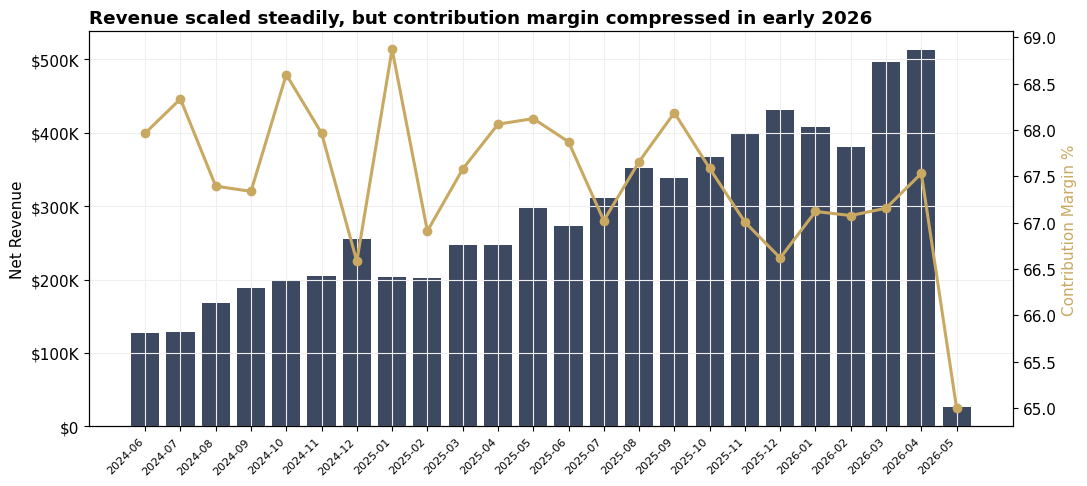

In [3]:
monthly = orders.groupby('ym').agg(net_revenue=('net_revenue','sum'),
        contribution_margin=('contribution_margin','sum')).reset_index()
monthly['cm_pct'] = monthly['contribution_margin']/monthly['net_revenue']
mr = monthly.tail(24)
fig, ax1 = plt.subplots(figsize=(11,5)); x = range(len(mr))
ax1.bar(x, mr['net_revenue'], color=NAVY, alpha=.85)
ax1.set_ylabel('Net Revenue'); ax1.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_usd))
ax2 = ax1.twinx(); ax2.plot(x, mr['cm_pct']*100, color=GOLD, marker='o', lw=2.2); ax2.grid(False)
ax2.set_ylabel('Contribution Margin %', color=GOLD)
ax1.set_xticks(list(x)); ax1.set_xticklabels(mr['ym'], rotation=45, ha='right', fontsize=8)
ax1.set_title('Revenue scaled steadily, but contribution margin compressed in early 2026', loc='left')
plt.tight_layout(); plt.show()

**So what?** The contribution-margin line confirms the diagnosis: profitability per revenue dollar
eroded even as the top line grew. The rest of the analysis isolates *why* (channel mix, segment mix,
and operational leaks) and what to do about it.

## Part 2: Customer & Growth

**Hypothesis:** value is highly concentrated in a few segments, and acquisition efficiency varies enough
between channels to justify reallocation. I validate the segments from behavior rather than trusting the label.

In [4]:
cust_orders = orders.groupby('customer_id').agg(
    orders=('order_id','count'), net_revenue=('net_revenue','sum'),
    contribution=('contribution_margin','sum')).reset_index()
cust_orders = cust_orders.merge(customers[['customer_id','segment','is_subscriber']], on='customer_id')
seg = cust_orders.groupby('segment').agg(customers=('customer_id','count'),
        total_revenue=('net_revenue','sum'), avg_ltv=('net_revenue','mean')).reset_index()
seg['rev_share'] = seg['total_revenue']/seg['total_revenue'].sum()
seg['cust_share'] = seg['customers']/seg['customers'].sum()
seg = seg.sort_values('total_revenue', ascending=False)
seg[['segment','customers','rev_share','cust_share','avg_ltv']].round(3)

,segment,customers,rev_share,cust_share,avg_ltv
5,VIP Longevity Loyalists,367,0.303,0.090,6558.001
0,Aesthetic Enthusiasts,602,0.196,0.148,2589.018
6,Wellness Curious,1246,0.175,0.306,1118.364
3,Lifestyle Buyers,741,0.154,0.182,1652.057
4,New Pet Parents,440,0.107,0.108,1933.378
1,Bargain Hunters,469,0.055,0.115,931.502
2,Churned,204,0.011,0.050,416.864


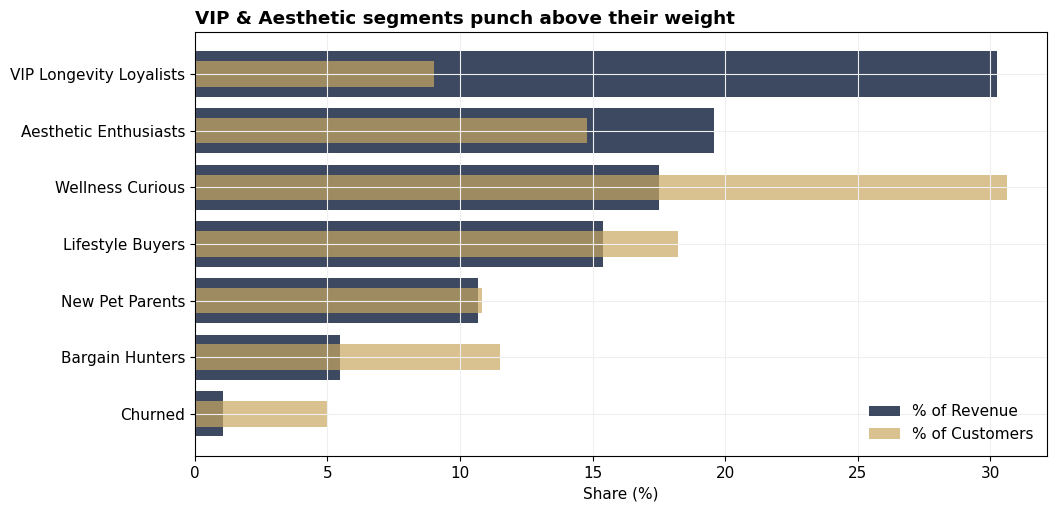

In [5]:
fig, ax = plt.subplots(figsize=(11,5.5)); y = range(len(seg))
ax.barh(y, seg['rev_share']*100, color=NAVY, alpha=.85, label='% of Revenue')
ax.barh(y, seg['cust_share']*100, color=GOLD, alpha=.7, height=.45, label='% of Customers')
ax.set_yticks(list(y)); ax.set_yticklabels(seg['segment']); ax.invert_yaxis()
ax.set_xlabel('Share (%)'); ax.legend(loc='lower right', frameon=False)
ax.set_title('VIP & Aesthetic segments punch above their weight', loc='left'); plt.show()

In [6]:
# Channel efficiency
mkt_ch = marketing.groupby('channel').agg(spend=('spend','sum'),
        new_customers=('new_customers','sum')).reset_index()
mkt_ch['cac'] = mkt_ch['spend']/mkt_ch['new_customers']
rev_ch = orders.groupby('channel').agg(net_revenue=('net_revenue','sum')).reset_index()
mkt_ch = mkt_ch.merge(rev_ch, on='channel', how='left')
mkt_ch['roas'] = mkt_ch['net_revenue']/mkt_ch['spend']
mkt_ch.sort_values('roas', ascending=False).round(2)

,channel,spend,new_customers,cac,net_revenue,roas
0,Email/Referral,102288.44,416,245.89,816267.05,7.98
4,Paid Social - TikTok,175946.85,249,706.61,552369.54,3.14
3,Paid Social - Meta,927459.78,1216,762.71,2338650.40,2.52
1,Influencer / Affiliate,509224.49,587,867.50,1047409.90,2.06
2,Paid Search - Google,736476.68,739,996.59,1369238.13,1.86
5,Podcast Sponsorship,171108.92,126,1358.01,179730.38,1.05


**So what?** Email/Referral returns 8x, Podcast barely 1.1x. There is a clean, defensible case to
move budget from the inefficient tail toward the efficient channels and toward retention.

In [7]:
# Subscription economics
sub = cust_orders.groupby('is_subscriber').agg(customers=('customer_id','count'),
        avg_ltv=('net_revenue','mean'), avg_orders=('orders','mean')).reset_index()
sub['label'] = sub['is_subscriber'].map({True:'Subscriber', False:'Non-Subscriber'})
sub[['label','customers','avg_ltv','avg_orders']].round(1)

,label,customers,avg_ltv,avg_orders
0,Non-Subscriber,3098,1556.1,5.0
1,Subscriber,971,3228.4,9.9


**So what?** Subscribers are worth ~2.1x non-subscribers. Subscription conversion is the single
highest-leverage retention lever in the business.

## Part 3: Product & Merchandising

**Hypothesis:** the categories that define the brand (Longevity, Grooming) are also the highest-margin,
so merchandising should pull customers toward them.

In [8]:
cat_prof = items.groupby('category').agg(revenue=('line_revenue','sum'),
        cogs=('line_cogs','sum'), units=('quantity','sum')).reset_index()
cat_prof['gm_pct'] = (cat_prof['revenue']-cat_prof['cogs'])/cat_prof['revenue']
cat_prof.sort_values('revenue', ascending=False).round(2)

,category,revenue,cogs,units,gm_pct
2,Longevity Supplements,3092618.0,686935.8,36255,0.78
1,Lifestyle & Home,1862796.0,659714.0,12834,0.65
3,Premium Nutrition,906246.0,318203.4,18214,0.65
0,Aesthetic Grooming,905532.0,150507.0,20187,0.83


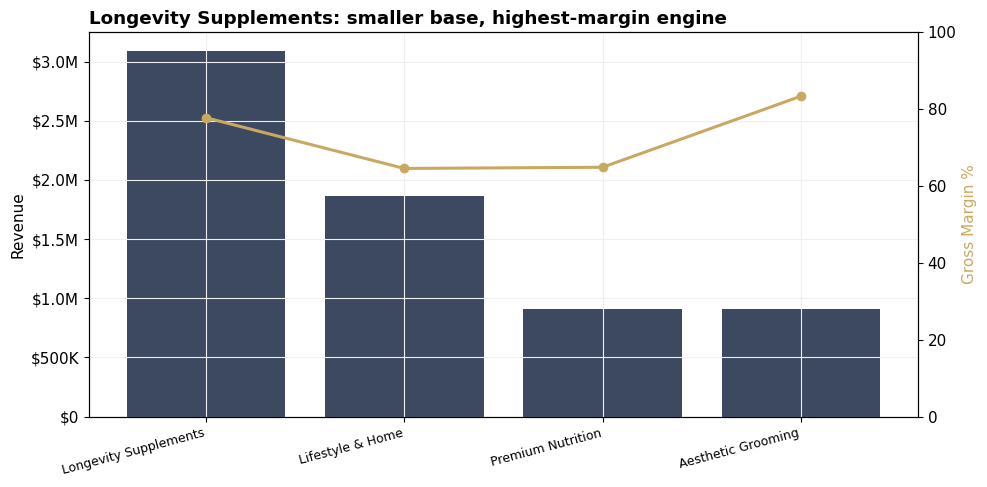

In [9]:
fig, ax1 = plt.subplots(figsize=(10,5)); cp = cat_prof.sort_values('revenue', ascending=False)
xc = range(len(cp)); ax1.bar(xc, cp['revenue'], color=NAVY, alpha=.85)
ax1.set_ylabel('Revenue'); ax1.yaxis.set_major_formatter(mticker.FuncFormatter(fmt_usd))
ax2 = ax1.twinx(); ax2.plot(xc, cp['gm_pct']*100, color=GOLD, marker='o', lw=2.2)
ax2.set_ylabel('Gross Margin %', color=GOLD); ax2.grid(False); ax2.set_ylim(0,100)
ax1.set_xticks(list(xc)); ax1.set_xticklabels(cp['category'], rotation=15, ha='right', fontsize=9)
ax1.set_title('Longevity Supplements: smaller base, highest-margin engine', loc='left'); plt.tight_layout(); plt.show()

## Part 4: Operations & Experience

**Hypothesis:** there are quantifiable contribution-margin leaks in returns, inventory, and support.

In [10]:
ord_seg = orders.merge(customers[['customer_id','segment']], on='customer_id')
ret = ord_seg.groupby('segment').apply(lambda d:(d['order_status']=='Returned').mean(),
        include_groups=False).reset_index(name='return_rate').sort_values('return_rate')
print(ret.round(3).to_string(index=False))
print(f"\nTicket rate: {len(tickets)/len(orders)*100:.0f}% of orders")
print(f"Overstock cash: ${(inventory[inventory.stock_status=='Overstocked']['units_on_hand']*inventory[inventory.stock_status=='Overstocked']['unit_cost']).sum():,.0f}")

                segment  return_rate
  Aesthetic Enthusiasts        0.056
       Wellness Curious        0.061
        New Pet Parents        0.061
VIP Longevity Loyalists        0.064
        Bargain Hunters        0.067
                Churned        0.101
       Lifestyle Buyers        0.115

Ticket rate: 18% of orders
Overstock cash: $56,016


**So what?** Lifestyle Buyers return at ~12% (double the base). A 2-point reduction in the highest-AOV
category is a direct margin win.

## Part 5: Strategic Recommendations

The full write-up lives in [`docs/RECOMMENDATIONS.md`](../docs/RECOMMENDATIONS.md). In brief:

| # | Initiative | Owner | Est. 12-mo impact |
|---|---|---|---|
| 1 | Reallocate spend to efficient channels + retention | Growth | +$180–260K margin |
| 2 | Subscription conversion program | Growth/CX | +$300–450K LTV |
| 3 | VIP & Aesthetic retention/expansion | CRM | +$200–320K revenue |
| 4 | Reduce Lifestyle return rate 2pts | Ops/Merch | +$45–70K margin |
| 5 | Bundle entry SKUs toward Longevity | Merch | +$120–180K margin |

**Where to play / How to win:** concentrate on the **VIP + Aesthetic customer × Longevity + Grooming
category × Email/Referral + subscription channel** intersection: the most profitable, most defensible
core of the business.

---
*Synthetic data, for demonstration. © Emma Larroze 2026.*